In [1]:
from google.colab import files

uploaded = files.upload()

Saving studentperformance_preprocessed.csv to studentperformance_preprocessed.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("studentperformance_preprocessed.csv")

In [6]:
print(df.head())

   gender race/ethnicity parental level of education         lunch  \
0  female        group b           bachelor's degree      standard   
1  female        group c                some college      standard   
2  female        group b             master's degree      standard   
3    male        group a          associate's degree  free/reduced   
4    male        group c                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


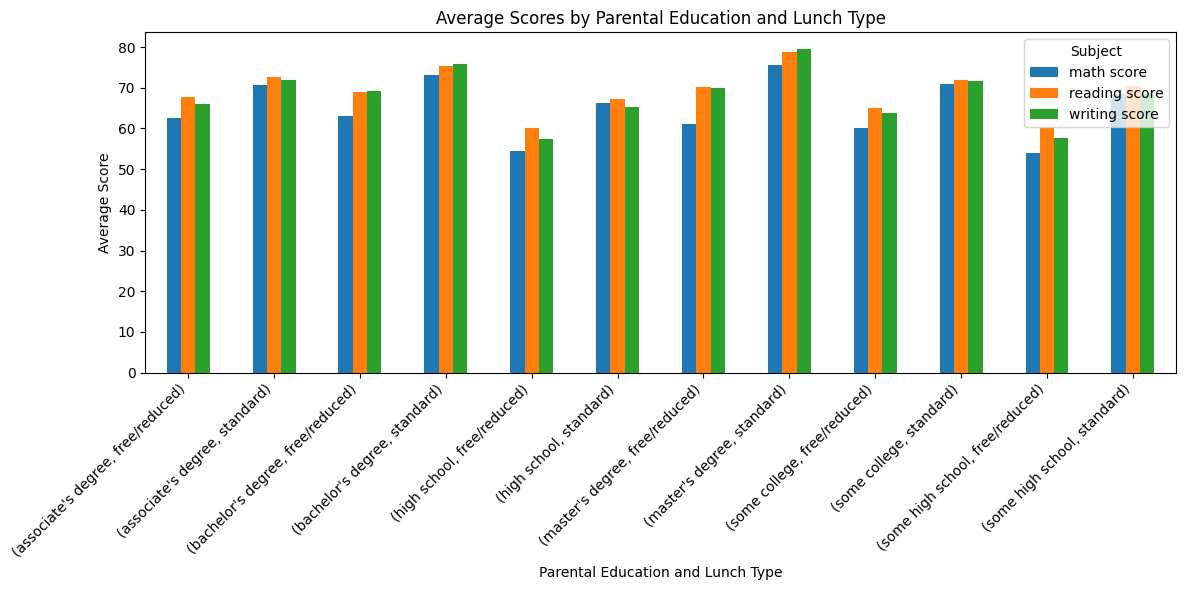

In [7]:
avg_scores = df.groupby(
    ["parental level of education", "lunch"]
)[["math score", "reading score", "writing score"]].mean()

avg_scores.plot(kind="bar", figsize=(12, 6))

plt.title("Average Scores by Parental Education and Lunch Type")
plt.xlabel("Parental Education and Lunch Type")
plt.ylabel("Average Score")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

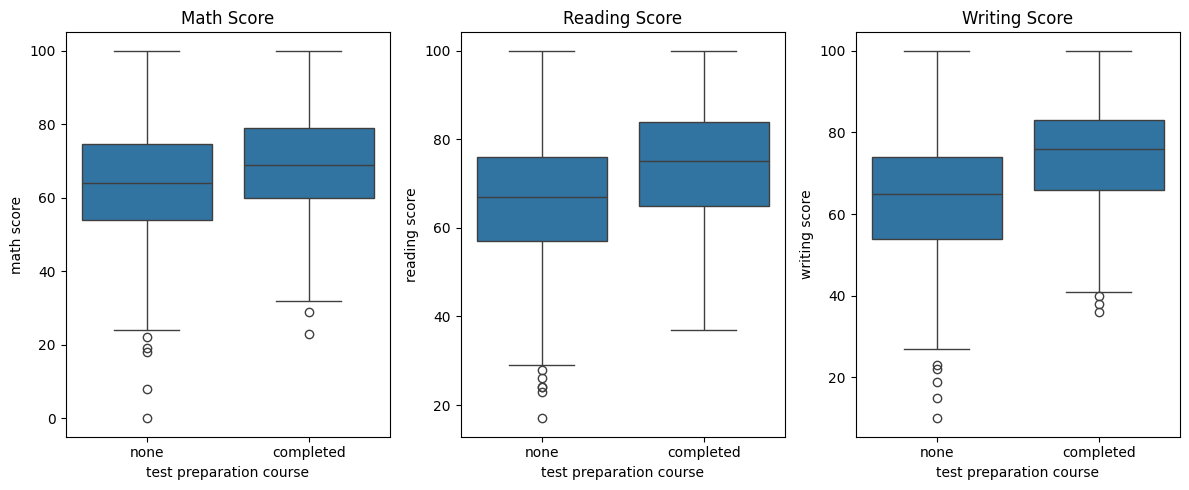

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
sns.boxplot(x="test preparation course", y="math score", data=df)
plt.title("Math Score")

plt.subplot(1, 3, 2)
sns.boxplot(x="test preparation course", y="reading score", data=df)
plt.title("Reading Score")

plt.subplot(1, 3, 3)
sns.boxplot(x="test preparation course", y="writing score", data=df)
plt.title("Writing Score")

plt.tight_layout()
plt.show()

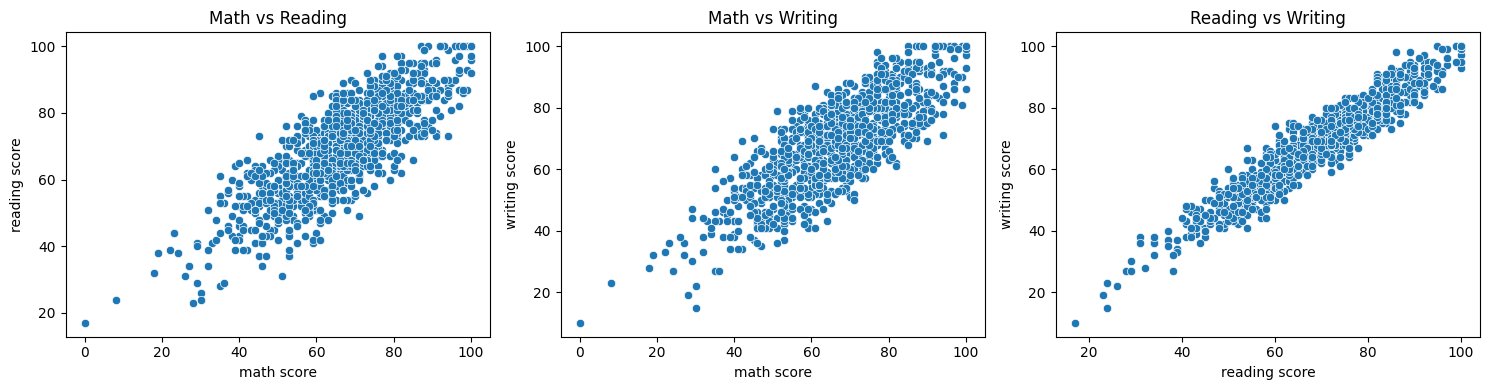

In [9]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(x="math score", y="reading score", data=df)
plt.title("Math vs Reading")

plt.subplot(1, 3, 2)
sns.scatterplot(x="math score", y="writing score", data=df)
plt.title("Math vs Writing")

plt.subplot(1, 3, 3)
sns.scatterplot(x="reading score", y="writing score", data=df)
plt.title("Reading vs Writing")

plt.tight_layout()
plt.show()



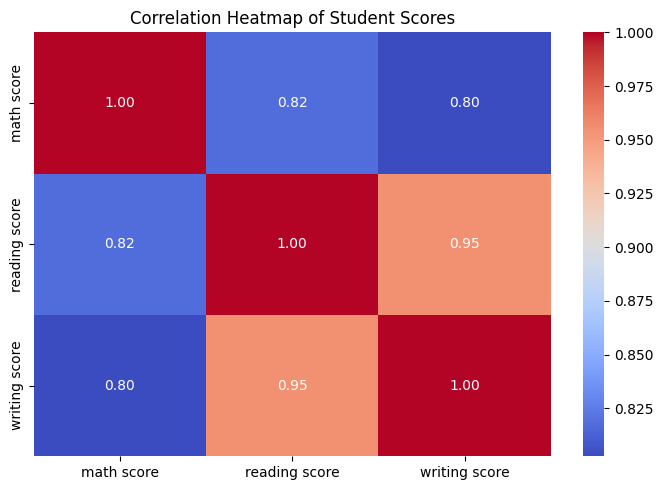

In [10]:
scores = df[["math score", "reading score", "writing score"]]

correlation = scores.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Student Scores")
plt.tight_layout()
plt.show()



In [11]:

print("\nAverage Scores by Parental Education:")
print(
    df.groupby("parental level of education")
    [["math score", "reading score", "writing score"]]
    .mean()
)

print("\nAverage Scores by Lunch Type:")
print(
    df.groupby("lunch")
    [["math score", "reading score", "writing score"]]
    .mean()
)

print("\nAverage Scores by Test Preparation:")
print(
    df.groupby("test preparation course")
    [["math score", "reading score", "writing score"]]
    .mean()
)

print("\nCorrelation between Scores:")
print(correlation)


Average Scores by Parental Education:
                             math score  reading score  writing score
parental level of education                                          
associate's degree            67.882883      70.927928      69.896396
bachelor's degree             69.389831      73.000000      73.381356
high school                   62.137755      64.704082      62.448980
master's degree               69.745763      75.372881      75.677966
some college                  67.128319      69.460177      68.840708
some high school              63.497207      66.938547      64.888268

Average Scores by Lunch Type:
              math score  reading score  writing score
lunch                                                 
free/reduced   58.921127      64.653521      63.022535
standard       70.034109      71.654264      70.823256

Average Scores by Test Preparation:
                         math score  reading score  writing score
test preparation course                        